# Estimação dos parâmetros do alimentador do Belvedere por ML com µPMUs

Reproduz, para o alimentador real do Belvedere (Cuiabá, BDGD + OpenDSS), o pipeline usado nos resultados do paper
(`feederlib.py`, nesta pasta), agora com todos os níveis de perturbação disponíveis (1 % a 29 %) e com o modelo de
ruído de D'Antona et al. (IEEE TIM, 2026).

| Item | Descrição |
|---|---|
| Trecho | barras `59911939827572667mt` (emissor, s) → `59912191827572000mt` (receptor, r), primeiro trecho do tronco |
| Dados | `0_0_09_…`, `0_1_0_19_…`, `0_2_0_29_resultados_perturbacoes_potencia.xlsx`, abas `pert_0.01` … `pert_0.29` |
| Entradas | $|V|$, $\angle V$, $|I|$, $\angle I$ e $P$, $Q$ por fase ($\mathbf S=\mathbf V\mathbf I^*$) no(s) terminal(is) medido(s) |
| Modelos | Ridge, MLP, LightGBM e Random Forest; referência: estimador bayesiano da equação da linha e limite teórico |
| Métrica | MAPE (%) por parâmetro no conjunto de teste (divisão 80/20) |

Experimentos:
- **E1 – Posição das µPMUs:** dois terminais, só o emissor e só o receptor; dados sem ruído, perturbação de 1 %.
- **E2 – Nível de perturbação:** 1 % a 29 %, dados sem ruído, µPMUs nos dois terminais.
- **E3 – Ruído de µPMU + TI:** escala $\alpha$ das amplitudes e número $K$ de *snapshots* sincronizados cuja média é
  usada; perturbação de 1 %, 9 % e 29 %.

**Modelo de ruído (E3).** Erro da µPMU: $\pm0{,}2\,\%$ e $\pm0{,}2$ crad, aleatório, sorteado a cada amostra (a média de
$K$ snapshots reduz o desvio-padrão por $1/\sqrt K$). Erro dos TIs classe 1: $\pm1\,\%$ e $\pm1{,}2$ crad (TP) ou
$\pm1{,}8$ crad (TC), **sistemático**: um sorteio por canal, fixo em todas as amostras e não reduzido pela média.
Todos uniformes, escalados por $\alpha$. As potências por fase são calculadas dos fasores medidos.
Treino e teste usam os TIs de `IT_SEED = 1`; as colunas *(unseen ITs)* repetem o teste com 10 outras realizações
dos TIs (cenário de campo). O estimador bayesiano trata o erro dos TIs como desconhecido.

Os experimentos levam ~20 min; o notebook usa `resultados_belvedere.pkl` se existir (`RECALCULAR = True` refaz tudo).

In [1]:
import os, pickle, time
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import feederlib as fl
from feederlib import PARAMS, GRUPOS

pd.set_option('display.precision', 3); pd.set_option('display.width', 180); pd.set_option('display.max_columns', 30)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.alpha': 0.3, 'font.size': 10, 'pdf.fonttype': 42})
COR = {'Ridge': '#2a78d6', 'MLP': '#eb6834', 'LightGBM': '#1baf7a', 'RandomForest': '#eda100',
       'Line-equation Bayes': '#6250d6', 'Line-equation bound': '#8a8984'}
FIG = 'figuras'; os.makedirs(FIG, exist_ok=True)
PKL = 'resultados_belvedere.pkl'
RECALCULAR = False

## 1. Dados e verificação do modelo físico

In [2]:
t0 = time.time()
dados = {lvl: fl.carregar(lvl) for lvl in fl.NIVEIS}
print(f'{len(dados)} níveis carregados em {time.time() - t0:.0f} s')

linhas = []
for lvl in (0.01, 0.09, 0.29):
    d = dados[lvl]
    dV = d['V1'] - d['V2']
    ell = fl.ajustar_ell(d['Y'], dV, d['I1'])
    res = dV - ell * np.einsum('nij,nj->ni', fl.matriz_Z(d['Y']), d['I1'])
    linhas.append({'nível': f'{100 * lvl:g} %', 'amostras': len(d['Y']),
                   'comprimento ajustado (m)': 1000 * ell,
                   '|V_s| (V)': np.abs(d['V1']).mean(), '|I| (A)': np.abs(d['I1']).mean(),
                   '|ΔV| (V)': np.abs(dV).mean(), '|ΔV|/|V_s|': (np.abs(dV) / np.abs(d['V1'])).mean(),
                   'resíduo |ΔV−ℓZI|/|ΔV|': np.abs(res).mean() / np.abs(dV).mean(),
                   'max |I_s+I_r| (A)': np.abs(d['I1'] + d['I2']).max(),
                   'dispersão dos parâmetros (%)': 100 * np.mean(d['Y'].std(0) / d['Y'].mean(0)),
                   'parâmetros ≤ 0': int((d['Y'] <= 0).sum())})
pd.DataFrame(linhas).set_index('nível').T

29 níveis carregados em 88 s


nível,1 %,9 %,29 %
amostras,1.000e+04,1.000e+04,1.000e+04
comprimento ajustado (m),7.130e+00,7.130e+00,7.130e+00
|V_s| (V),8.198e+03,8.198e+03,8.198e+03
|I| (A),3.158e+02,3.158e+02,3.158e+02
|ΔV| (V),7.594e-01,7.805e-01,1.010e+00
|ΔV|/|V_s|,9.263e-05,9.521e-05,1.232e-04
resíduo |ΔV−ℓZI|/|ΔV|,5.081e-07,5.082e-07,5.082e-07
max |I_s+I_r| (A),3.739e-04,3.740e-04,3.740e-04
dispersão dos parâmetros (%),9.989e-01,9.008e+00,2.915e+01
parâmetros ≤ 0,0.000e+00,0.000e+00,3.500e+01


Os dados seguem $\Delta\mathbf V=\ell\,\mathbf Z\,\mathbf I$ com resíduo de $\sim10^{-6}$ de $|\Delta\mathbf V|$ e $\ell = 7{,}13$ m:
são simulações **sem ruído** de um trecho muito curto, com queda de tensão de $\sim10^{-4}$ da tensão de fase. Nos
níveis mais altos aparecem alguns parâmetros negativos (perturbação gaussiana com desvio-padrão relativo igual ao nível),
que inflam o MAPE desses parâmetros; por isso a figura do E2 vai só até 25 %.

## 2. Execução (ou carga) dos experimentos

In [3]:
ALPHAS, KS = [1.0, 0.1, 0.01], [1, 10, 100]
SPREADS_E3 = [0.01, 0.09, 0.29]

def rodar_tudo():
    R = {}
    def run(key, d, **kw):
        t0 = time.time(); tab, _ = fl.experimento(d, **kw); R[key] = tab
        print(key, f'{time.time() - t0:5.1f}s', tab.mean().round(3).to_dict(), flush=True)
    for cfg in fl.CONFIGS:                                   # E1
        run(('E1', cfg), dados[0.01], config=cfg)
    for lvl in fl.NIVEIS:                                    # E2
        run(('E2', lvl), dados[lvl], config='both', rapido=True)
    for lvl in SPREADS_E3:                                   # E3
        for a in ALPHAS:
            for K in KS:
                run(('E3', lvl, a, K), dados[lvl], config='both', alpha=a, K=K, rapido=True)
    return R

if RECALCULAR or not os.path.exists(PKL):
    R = rodar_tudo()
    pickle.dump(R, open(PKL, 'wb'))
R = pickle.load(open(PKL, 'rb'))
print(len(R), 'experimentos')
MODELOS = ['Ridge', 'MLP', 'LightGBM', 'RandomForest']
REFS = ['Line-equation Bayes', 'Line-equation bound']

def grupos(tab):
    g = pd.DataFrame({k: tab.loc[v].mean() for k, v in GRUPOS.items()}).T
    g.loc['All 12 parameters'] = tab.mean()
    return g

59 experimentos


## 3. E1 – Posição das µPMUs (dados sem ruído, perturbação de 1 %)

In [4]:
print('MAPE (%) por parâmetro — µPMUs nos dois terminais')
display(R[('E1', 'both')].round(3))
e1 = {}
for cfg, rot in fl.CONFIGS.items():
    g = grupos(R[('E1', cfg)])
    for m in g.columns:
        e1[(rot, m)] = g[m]
e1 = pd.DataFrame(e1).T
e1.index.names = ['µPMU placement', 'model']
print('MAPE médio (%) por grupo de parâmetros')
display(e1.round(3))

MAPE (%) por parâmetro — µPMUs nos dois terminais


,Ridge,MLP,LightGBM,RandomForest,Line-equation Bayes,Line-equation bound
r11,0.571,0.573,0.581,0.593,0.571,0.573
r12,0.791,0.794,0.810,0.803,0.790,0.792
r22,0.689,0.692,0.701,0.707,0.690,0.671
r13,0.798,0.803,0.814,0.812,0.798,0.789
r23,0.783,0.789,0.800,0.802,0.783,0.791
r33,0.667,0.667,0.684,0.692,0.664,0.649
x11,0.270,0.281,0.278,0.288,0.270,0.268
x12,0.412,0.417,0.419,0.423,0.411,0.410
x22,0.275,0.282,0.283,0.287,0.274,0.276
x13,0.431,0.438,0.444,0.452,0.431,0.423


MAPE médio (%) por grupo de parâmetros


Reactances  Self resistances  Mutual resistances  All 12 parameters
µPMU placement             model                                                                                   
µPMU at both terminals     Ridge                     0.346             0.642               0.791              0.531
                           MLP                       0.353             0.644               0.795              0.537
                           LightGBM                  0.356             0.655               0.808              0.544
                           RandomForest              0.362             0.664               0.806              0.549
                           Line-equation Bayes       0.346             0.642               0.790              0.531
                           Line-equation bound       0.343             0.631               0.791              0.527
µPMU at sending end only   Ridge                     0.359             0.642               0.791              0.537
                           MLP                       0.577             0.657               0.796              0.652
                           LightGBM                  0.585             0.670               0.811              0.662
                           RandomForest              0.591             0.677               0.812              0.668
µPMU at receiving end only Ridge                     0.346             0.642               0.791              0.531
                           MLP                       0.349             0.645               0.793              0.534
                           LightGBM                  0.357             0.659               0.808              0.545
                           RandomForest              0.364             0.671               0.806              0.551

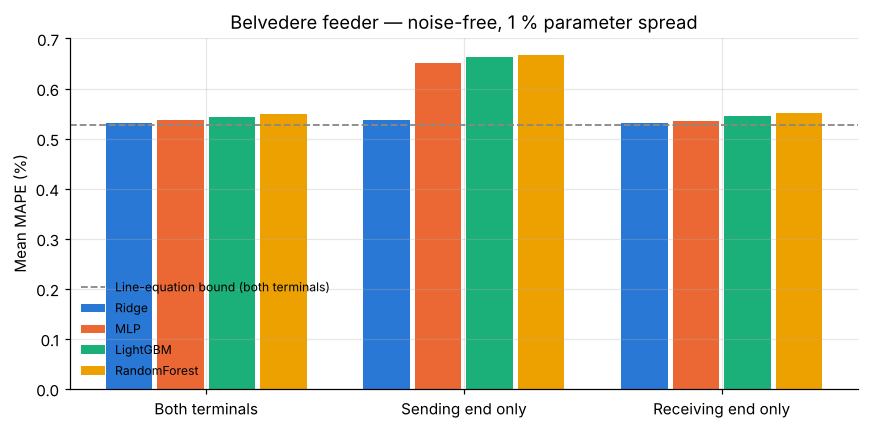

In [5]:
fig, ax = plt.subplots(figsize=(8, 4))
cfgs, w = list(fl.CONFIGS), 0.2
for k, m in enumerate(MODELOS):
    ax.bar(np.arange(3) + (k - 1.5) * w, [R[('E1', c)][m].mean() for c in cfgs], width=w - 0.02, color=COR[m], label=m)
ax.axhline(R[('E1', 'both')]['Line-equation bound'].mean(), color=COR['Line-equation bound'], ls='--', lw=1.2,
           label='Line-equation bound (both terminals)')
ax.set_xticks(range(3), ['Both terminals', 'Sending end only', 'Receiving end only'])
ax.set_ylabel('Mean MAPE (%)'); ax.set_title('Belvedere feeder — noise-free, 1 % parameter spread')
ax.legend(frameon=False, fontsize=8, loc='lower left')
plt.tight_layout(); plt.savefig(f'{FIG}/E1_placement_belvedere.pdf', bbox_inches='tight'); plt.show()

## 4. E2 – Nível de perturbação (dados sem ruído, µPMUs nos dois terminais)

In [6]:
e2 = pd.DataFrame({lvl: R[('E2', lvl)].mean() for lvl in fl.NIVEIS}).T
e2.index = [f'{100 * l:g} %' for l in fl.NIVEIS]; e2.index.name = 'parameter spread'
e2['parâmetros ≤ 0'] = [int((dados[l]['Y'] <= 0).sum()) for l in fl.NIVEIS]
display(e2.round(3))

e2g = pd.DataFrame({(f'{100 * l:g} %', g): R[('E2', l)].loc[GRUPOS[g], 'Ridge'].mean()
                    for l in fl.NIVEIS for g in GRUPOS}, index=['Ridge']).T.unstack()
e2g = e2g.reindex([f'{100 * l:g} %' for l in fl.NIVEIS])
print('Ridge — MAPE médio (%) por grupo')
display(e2g.round(3))

,Ridge,MLP,LightGBM,Line-equation Bayes,Line-equation bound,parâmetros ≤ 0
parameter spread,,,,,,
1 %,0.531,0.537,0.544,0.531,0.527,0
2 %,1.053,1.061,1.080,1.052,1.053,0
3 %,1.571,1.582,1.614,1.570,1.581,0
4 %,2.112,2.132,2.166,2.111,2.117,0
5 %,2.654,2.671,2.724,2.653,2.636,0
6 %,3.209,3.240,3.282,3.208,3.183,0
7 %,3.767,3.795,3.859,3.767,3.712,0
8 %,4.331,4.365,4.431,4.329,4.235,0
9 %,4.765,4.816,4.898,4.763,4.798,0


Ridge — MAPE médio (%) por grupo


Ridge                            
     Mutual resistances Reactances Self resistances
1 %               0.791      0.346            0.642
2 %               1.575      0.685            1.268
3 %               2.385      1.007            1.884
4 %               3.119      1.394            2.543
5 %               3.992      1.723            3.179
6 %               4.780      2.073            3.908
7 %               5.587      2.469            4.545
8 %               6.404      2.878            5.165
9 %               7.265      3.066            5.665
10 %              8.134      3.637            6.538
11 %              8.996      3.908            7.028
12 %              9.698      4.183            7.884
13 %             10.818      4.645            8.584
14 %             11.428      5.000            9.105
15 %             12.401      5.196           10.012
16 %             13.291      5.717           10.785
17 %             14.400      6.171           11.310
18 %             15.480      6.392           11.893
19 %             16.284      6.862           12.992
20 %             17.401      7.225           13.971
21 %             18.014      7.811           14.559
22 %             19.155      8.193           15.433
23 %             21.372      8.704           16.481
24 %             21.974      9.108           16.919
25 %             23.317      9.204           18.442
26 %             25.618     10.152           32.083
27 %             25.985     10.702           20.086
28 %            213.015     15.315           22.245
29 %             30.121     11.803           22.648

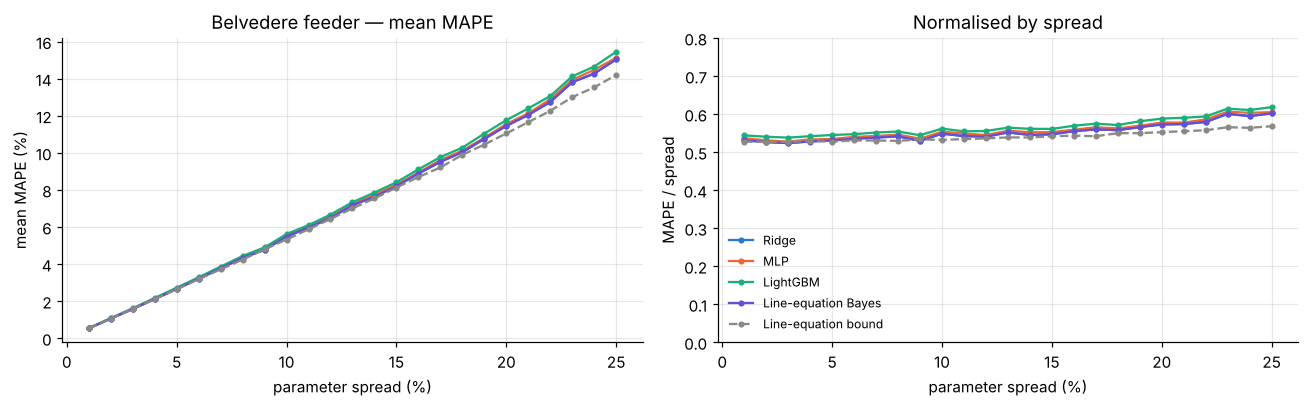

In [7]:
# figura até 25 %: acima disso há parâmetros ≤ 0 e o MAPE perde o sentido
n25 = [l for l in fl.NIVEIS if l <= 0.25 + 1e-9]
pct = np.array([100 * l for l in n25])
e2p = e2.iloc[:len(n25)]
fig, axs = plt.subplots(1, 2, figsize=(12, 3.8))
for m in ['Ridge', 'MLP', 'LightGBM', 'Line-equation Bayes', 'Line-equation bound']:
    ls = '--' if m == 'Line-equation bound' else '-'
    axs[0].plot(pct, e2p[m], ls=ls, marker='o', ms=3, color=COR[m], label=m)
    axs[1].plot(pct, e2p[m] / pct, ls=ls, marker='o', ms=3, color=COR[m], label=m)
axs[0].set_xlabel('parameter spread (%)'); axs[0].set_ylabel('mean MAPE (%)'); axs[0].set_title('Belvedere feeder — mean MAPE')
axs[1].set_xlabel('parameter spread (%)'); axs[1].set_ylabel('MAPE / spread'); axs[1].set_ylim(0, 0.8)
axs[1].set_title('Normalised by spread'); axs[1].legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.savefig(f'{FIG}/E2_spread_belvedere.pdf', bbox_inches='tight'); plt.show()

## 5. E3 – Ruído de µPMU + transformadores de instrumentos

Colunas sem sufixo: treino e teste com os mesmos TIs (`IT_SEED = 1`). Colunas *(unseen ITs)*: mesmo modelo, testado
com 10 outras realizações dos TIs. O estimador bayesiano e o limite tratam o erro dos TIs como desconhecido.

In [8]:
COLS_E3 = ['Ridge', 'Ridge (unseen ITs)', 'MLP', 'MLP (unseen ITs)', 'LightGBM', 'LightGBM (unseen ITs)',
           'Line-equation Bayes', 'Line-equation bound']

def tabela_e3(lvl):
    rows = {('noise-free', '–'): R[('E1', 'both')].mean() if lvl == 0.01 else R[('E2', lvl)].mean()}
    for a in ALPHAS:
        for K in KS:
            rows[(f'α = {a:g}', f'K = {K}')] = R[('E3', lvl, a, K)].mean()
    t = pd.DataFrame(rows).T
    t.index.names = ['noise scale', 'snapshots']
    return t[[c for c in COLS_E3 if c in t]]

for lvl in SPREADS_E3:
    print(f'===== Perturbação de {100 * lvl:g} % — MAPE médio (%)')
    display(tabela_e3(lvl).round(3))

===== Perturbação de 1 % — MAPE médio (%)


Ridge  Ridge (unseen ITs)    MLP  MLP (unseen ITs)  LightGBM  LightGBM (unseen ITs)  Line-equation Bayes  Line-equation bound
noise scale snapshots                                                                                                                               
noise-free  –          0.531                 NaN  0.537               NaN     0.544                    NaN                0.531                0.527
α = 1       K = 1      0.802               2.638  0.805             1.576     0.812                  0.868                0.800                0.796
            K = 10     0.801              15.746  0.805             4.458     0.812                  0.874                0.800                0.796
            K = 100    0.801              23.582  0.805            15.458     0.813                  0.852                0.800                0.796
α = 0.1     K = 1      0.801               0.922  0.805             1.568     0.810                  0.922                0.800                0.796
            K = 10     0.798               2.561  0.803             4.380     0.810                  0.878                0.800                0.796
            K = 100    0.782              14.380  0.789            17.485     0.795                  0.886                0.800                0.796
α = 0.01    K = 1      0.782               1.693  0.788             1.852     0.768                  1.050                0.800                0.796
            K = 10     0.705               7.029  0.714             7.697     0.719                  0.987                0.800                0.796
            K = 100    0.595              15.908  0.604            17.772     0.608                  1.166                0.800                0.796

===== Perturbação de 9 % — MAPE médio (%)


Ridge  Ridge (unseen ITs)    MLP  MLP (unseen ITs)  LightGBM  LightGBM (unseen ITs)  Line-equation Bayes  Line-equation bound
noise scale snapshots                                                                                                                               
noise-free  –          4.765                 NaN  4.816               NaN     4.898                    NaN                4.763                4.798
α = 1       K = 1      7.278              26.969  7.313            11.638     7.347                  8.033                7.262                7.251
            K = 10     7.258             148.742  7.301            38.233     7.372                  8.063                7.262                7.251
            K = 100    7.127             249.892  7.195           129.044     7.241                  8.252                7.262                7.251
α = 0.1     K = 1      7.141              15.532  7.201            15.288     6.987                  9.150                7.260                7.250
            K = 10     6.474              59.666  6.574            60.762     6.594                  8.815                7.260                7.250
            K = 100    5.427             143.203  5.521           174.770     5.557                 10.781                7.260                7.250
α = 0.01    K = 1      5.440              16.866  5.538            18.704     5.560                  9.956                7.247                7.151
            K = 10     4.887              22.877  4.987            33.515     5.022                 11.081                7.247                7.148
            K = 100    4.782              30.443  4.857            59.871     4.927                 12.122                7.248                7.148

===== Perturbação de 29 % — MAPE médio (%)


Ridge  Ridge (unseen ITs)     MLP  MLP (unseen ITs)  LightGBM  LightGBM (unseen ITs)  Line-equation Bayes  Line-equation bound
noise scale snapshots                                                                                                                                 
noise-free  –          19.094                 NaN  19.224               NaN    19.641                    NaN               19.085               17.438
α = 1       K = 1      30.876              87.284  31.011            56.185    30.650                 35.317               30.875               26.412
            K = 10     30.011             444.498  30.314           169.116    30.415                 33.451               30.875               26.412
            K = 100    26.667            1108.567  27.094           752.775    27.143                 36.261               30.875               26.412
α = 0.1     K = 1      26.804              80.010  27.129            87.229    26.584                 38.652               30.881               26.372
            K = 10     21.855             174.261  22.213           195.426    22.446                 42.178               30.880               26.371
            K = 100    19.570             261.992  19.920           294.271    20.151                 47.535               30.880               26.370
α = 0.01    K = 1      19.547              34.116  19.901            44.523    20.263                 31.234               28.557               23.878
            K = 10     19.157              40.680  19.494            67.261    19.750                 33.886               28.523               23.829
            K = 100    19.132             103.565  19.469           175.997    19.701                 34.235               28.521               23.824

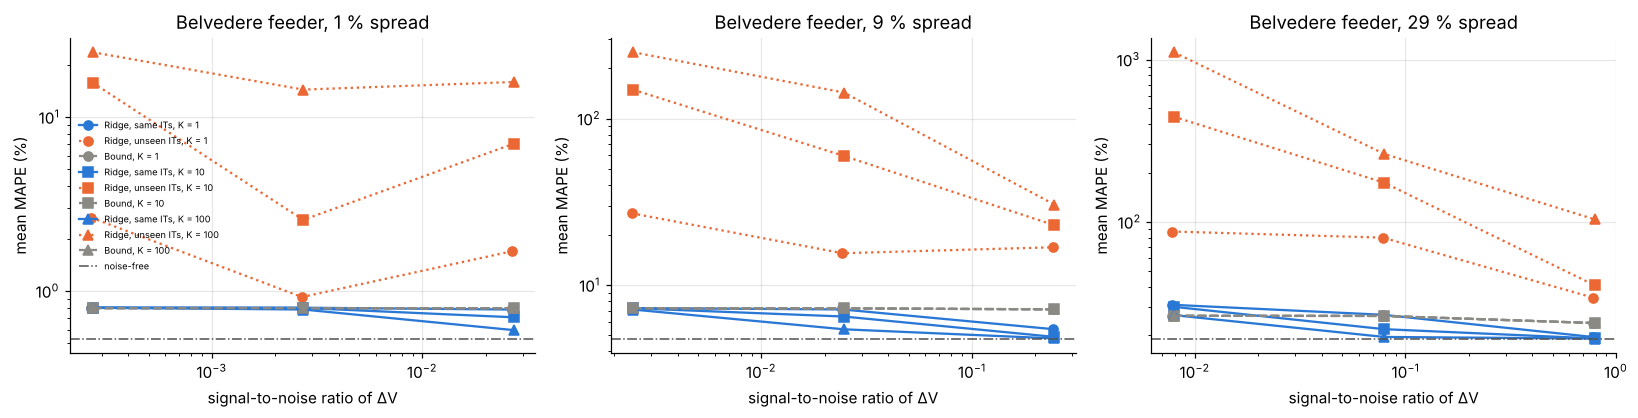

In [9]:
def snr(d, alpha, K):
    # SNR da queda de tensão: dispersão de ΔV causada pelos parâmetros / erro da diferença de duas tensões
    sm, sav, _ = fl.sigmas(alpha, K)
    sig_noise = np.sqrt(2) * np.abs(d['V1']).mean() * np.sqrt(sm ** 2 + sav ** 2)
    dV = d['V1'] - d['V2']
    return np.sqrt(np.mean(np.abs(dV - dV.mean(0)) ** 2)) / sig_noise

fig, axs = plt.subplots(1, 3, figsize=(15, 3.9))
for ax, lvl in zip(axs, SPREADS_E3):
    d = dados[lvl]
    for K, mk in zip(KS, ['o', 's', '^']):
        xs = [snr(d, a, K) for a in ALPHAS]
        ax.plot(xs, [R[('E3', lvl, a, K)]['Ridge'].mean() for a in ALPHAS], marker=mk, color=COR['Ridge'],
                label=f'Ridge, same ITs, K = {K}')
        ax.plot(xs, [R[('E3', lvl, a, K)]['Ridge (unseen ITs)'].mean() for a in ALPHAS], marker=mk, ls=':',
                color=COR['MLP'], label=f'Ridge, unseen ITs, K = {K}')
        ax.plot(xs, [R[('E3', lvl, a, K)]['Line-equation bound'].mean() for a in ALPHAS], marker=mk, ls='--',
                color=COR['Line-equation bound'], label=f'Bound, K = {K}')
    base = R[('E1', 'both')] if lvl == 0.01 else R[('E2', lvl)]
    ax.axhline(base['Ridge'].mean(), color='#52514e', lw=1, ls='-.', label='noise-free')
    ax.set_xscale('log'); ax.set_yscale('log')
    ax.set_xlabel('signal-to-noise ratio of ΔV'); ax.set_ylabel('mean MAPE (%)')
    ax.set_title(f'Belvedere feeder, {100 * lvl:g} % spread')
axs[0].legend(frameon=False, fontsize=6)
plt.tight_layout(); plt.savefig(f'{FIG}/E3_noise_belvedere.pdf', bbox_inches='tight'); plt.show()

## 6. Síntese

In [10]:
s = {
    'Sem ruído, 1 %, dois terminais (Ridge)': R[('E1', 'both')]['Ridge'].mean(),
    'Sem ruído, 1 %, limite da equação da linha': R[('E1', 'both')]['Line-equation bound'].mean(),
    'Sem ruído, 1 %, só receptor (Ridge)': R[('E1', 'receiving')]['Ridge'].mean(),
    'Sem ruído, 1 %, só emissor (Ridge)': R[('E1', 'sending')]['Ridge'].mean(),
    'Sem ruído, 29 % (Ridge)': R[('E2', 0.29)]['Ridge'].mean(),
    'Ruído nominal, 1 %, mesmos TIs (Ridge)': R[('E3', 0.01, 1.0, 1)]['Ridge'].mean(),
    'Ruído nominal, 1 %, TIs não vistos (Ridge)': R[('E3', 0.01, 1.0, 1)]['Ridge (unseen ITs)'].mean(),
    'Ruído nominal, 29 %, mesmos TIs (Ridge)': R[('E3', 0.29, 1.0, 1)]['Ridge'].mean(),
    'Ruído nominal, 29 %, limite': R[('E3', 0.29, 1.0, 1)]['Line-equation bound'].mean(),
}
pd.Series(s, name='MAPE médio (%)').round(3).to_frame()

,MAPE médio (%)
"Sem ruído, 1 %, dois terminais (Ridge)",0.531
"Sem ruído, 1 %, limite da equação da linha",0.527
"Sem ruído, 1 %, só receptor (Ridge)",0.531
"Sem ruído, 1 %, só emissor (Ridge)",0.537
"Sem ruído, 29 % (Ridge)",19.094
"Ruído nominal, 1 %, mesmos TIs (Ridge)",0.802
"Ruído nominal, 1 %, TIs não vistos (Ridge)",2.638
"Ruído nominal, 29 %, mesmos TIs (Ridge)",30.876
"Ruído nominal, 29 %, limite",26.412
